# BIFlow — Dashboard intelligent (Étape 6, BO4)

## 1. Introduction

### Problème
Un dashboard peut être **techniquement exact et pourtant trompeur** : camembert à 27 parts, courbe qui relie deux points séparés par un trou, comparaison d'un mois complet avec un mois partiel, « +6400 % » issu d'une base minuscule.

### Objectif
À partir de la question de Sarra, des métriques calculées par l'Analyst et du rapport de comparabilité (BO4-12) :
1. **choisir automatiquement le type de graphique optimal** (et expliquer pourquoi les autres ont été écartés) ;
2. **refuser un graphique demandé s'il trompe**, avec la raison ;
3. **détecter les pièges visuels** et ne pas tracer une comparaison bloquée sans la décision de Sarra ;
4. fournir à l'Auditor la trace complète de ces décisions.

### Rôles respectifs
| Agent | Juge | Question |
|---|---|---|
| `comparisons/` (Tasnim, BO4-12) | les **données** | les deux périodes sont-elles comparables ? |
| `dashboard_ai/` (ce notebook) | l'**image** | le graphique, tel que dessiné, mène-t-il à une mauvaise lecture ? |

## 2. Architecture

```
AnalysisRequest + AnalysisResult + result.parquet + ComparisonReport
                      │
        intent.py  ── que veut voir la question ? (tendance, part, classement, comparaison, détail
                      │                              + graphique demandé explicitement)
        profile.py ── nature des axes, cardinalité, KPI additif ?, valeurs négatives ?
                      │
        selector.py ─ score de chaque ChartType + raisons (retenu / écarté)
                      │
        misleading.py ─ pièges visuels      prepare.py ─ données prêtes à tracer (top N, tri, alignement)
                      │
        agent.py ──► dashboard_spec.json (contrat inchangé) + chart_advice.json (preuve pour l'Auditor)
```
Seuils : `dashboard_ai/rules.py` (versionné, comme `comparisons/rules.py`).

## 3. Environment Setup

In [1]:
import sys, json, tempfile
from pathlib import Path
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

repo_root = Path.cwd().resolve()
for _ in range(6):
    if (repo_root / 'contracts').exists():
        break
    repo_root = repo_root.parent
assert (repo_root / 'contracts').exists(), f"Cannot find repo root from {Path.cwd()}"
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
print(f"Repo root: {repo_root}")
print(f"Python: {sys.version.split()[0]}")

Repo root: /home/claude/BIfloww
Python: 3.12.3


## 4. Règles versionnées

Tous les seuils sont au même endroit. Les modifier = incrémenter `RULES_VERSION` ; le journal d'audit enregistre la version qui a décidé.

In [2]:
from dashboard_ai.rules import DEFAULT, RULES_VERSION
print(RULES_VERSION)
pd.Series(DEFAULT.as_evidence()).to_frame('valeur')

dashboard-rules@1.0


,valeur
rules_version,dashboard-rules@1.0
pie_min_slices,2
pie_max_slices,6
bar_max_categories,15
line_min_points,3
dominant_share,0.8
base_effect_ratio,10.0
small_difference,0.05
map_enabled,False


## 5. Intention de la question

Lecture FR/EN de la **forme** du souhait (BO4-06 a déjà extrait métrique, dimensions et périodes).

In [3]:
from dashboard_ai.intent import detect_intent, detect_requested_chart

tests = [
    ("Quel est le CA total d'août ?",                     dict(n_dims=0, temporal=False, has_comparison=False)),
    ("Évolution du CA par mois",                          dict(n_dims=1, temporal=True,  has_comparison=False)),
    ("Répartition du CA par type de paiement",            dict(n_dims=1, temporal=False, has_comparison=False)),
    ("Top des états par chiffre d'affaires",              dict(n_dims=1, temporal=False, has_comparison=False)),
    ("CA par état, août vs juillet",                      dict(n_dims=1, temporal=False, has_comparison=True)),
    ("CA par état en camembert",                          dict(n_dims=1, temporal=False, has_comparison=False)),
]
pd.DataFrame([{"question": q, "intention": detect_intent(q, **kw).value,
               "graphique demandé": (detect_requested_chart(q).value if detect_requested_chart(q) else "-")}
              for q, kw in tests])

,question,intention,graphique demandé
0,Quel est le CA total d'août ?,total,-
1,Évolution du CA par mois,trend,-
2,Répartition du CA par type de paiement,composition,-
3,Top des états par chiffre d'affaires,ranking,-
4,"CA par état, août vs juillet",comparison,-
5,CA par état en camembert,none,pie


## 6. Choix du graphique : score + raisons

Chaque type reçoit un score **et** une liste de raisons. Un type est *inéligible* s'il ne peut pas dire la vérité avec ces données (camembert > 6 parts, KPI non additif, valeurs négatives, courbe sans axe temporel, < 3 points…).


=== pie_share ===
Question : Revenue share by payment type
Lesson   : Share of a whole, 4 slices, additive KPI -> pie is allowed and chosen.
Chosen   : pie   (intent=composition, requested=-, comparison_shown=False)
Ranking  :
   OK pie         85  Part d'un tout sur 4 secteurs d'un KPI additif.
   OK bar         75  Dimension catégorielle (4 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no line         0  L'axe x (payment_type) n'est pas temporel : une ligne impliquerait un ordre qui n'existe pas.
   no map          0  L'application n'a pas encore de rendu cartographique.


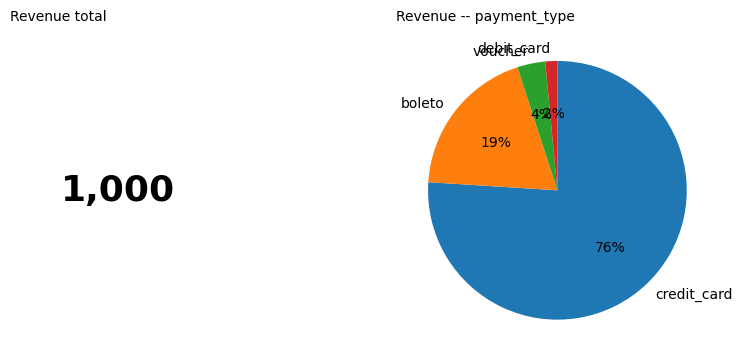

In [4]:
from dashboard_ai.lab.lab_dashboard import scenarios, run_scenario, describe
from dashboard_ai.render import figure
SC = {s.name: s for s in scenarios()}

def show(name, lang="fr"):
    s = SC[name]
    spec, advice, frames = run_scenario(s, lang)
    print(describe(s, spec, advice))
    fig = figure(spec.charts, frames, spec.warnings)
    display(fig); plt.close(fig)
    return spec, advice, frames

_ = show("pie_share")

### 6.1 Le camembert demandé mais trompeur

Sarra demande « en camembert » pour 27 états : le graphique est **refusé avec la raison**, et remplacé.


=== pie_27 ===
Question : Revenue by state as a pie chart
Lesson   : The user asked for a pie: refused (27 slices), a bar is drawn with the reason.
Chosen   : bar   (intent=none, requested=pie, comparison_shown=False)
Ranking  :
   OK bar         70  Dimension catégorielle (27 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no line         0  L'axe x (customer_state) n'est pas temporel : une ligne impliquerait un ordre qui n'existe pas.
   no pie          0  Un camembert à 27 parts est illisible (max 6) : on ne compare pas de petits angles à l'œil.
   no map          0  L'application n'a pas encore de rendu cartographique.
   ! Vous avez demandé un camembert, mais ce serait trompeur : Un camembert à 27 parts est illisible (max 6) : on ne compare pas de petits angles à l'œil. Remplacé par : barres.
   

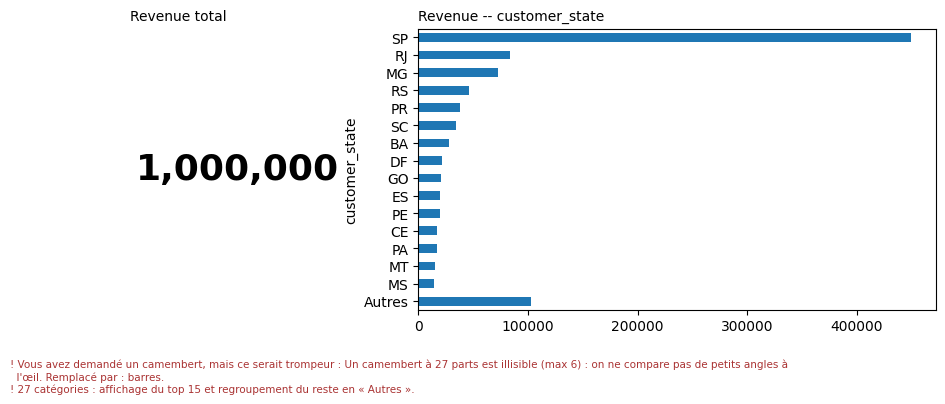

In [5]:
_ = show("pie_27")


=== pie_distinct ===
Question : Customers by payment type as a pie chart
Lesson   : Distinct counts do not add up (a customer can use 2 payment types): pie refused.
Chosen   : bar   (intent=none, requested=pie, comparison_shown=False)
Ranking  :
   OK bar         75  Dimension catégorielle (3 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no line         0  L'axe x (payment_type) n'est pas temporel : une ligne impliquerait un ordre qui n'existe pas.
   no pie          0  Customers n'est pas additif (comptage distinct ou moyenne) : ses parts ne forment pas un tout.
   no map          0  L'application n'a pas encore de rendu cartographique.
   ! Vous avez demandé un camembert, mais ce serait trompeur : Customers n'est pas additif (comptage distinct ou moyenne) : ses parts ne forment pas un tout. Rempla

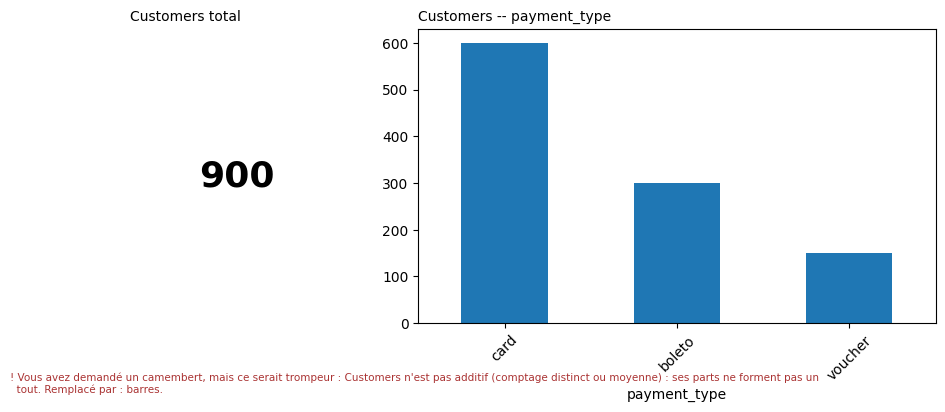

In [6]:
spec, advice, _ = show("pie_distinct")
# Un comptage distinct n'est pas additif : un client peut utiliser deux moyens de paiement.
assert advice.decisions[-1].chosen.value != "pie"

## 7. Séries temporelles : le trou caché

Une courbe relie les points voisins : si deux mois manquent, elle les **efface visuellement**.


=== line_trend ===
Question : Evolution of revenue per month
Lesson   : Time axis, 8 points -> line.
Chosen   : line   (intent=trend, requested=-, comparison_shown=False)
Ranking  :
   OK line        95  Axe temporel de 8 points : la ligne montre la tendance.
   OK bar         50  Dimension catégorielle (8 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no pie          0  Un camembert demande exactement une dimension catégorielle.
   no map          0  L'application n'a pas encore de rendu cartographique.


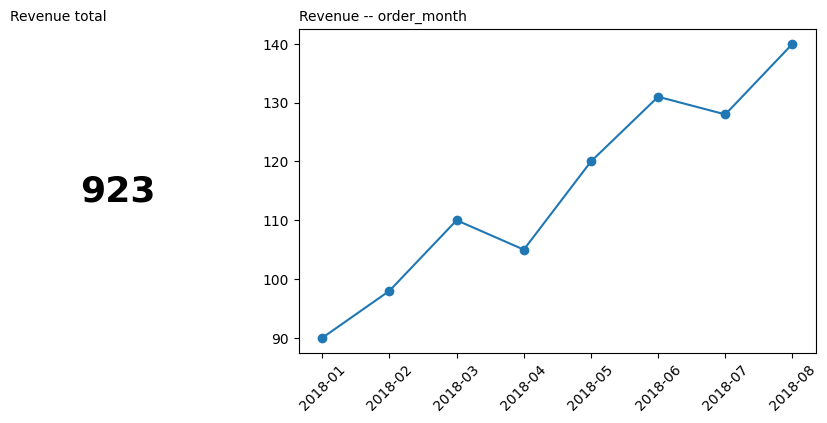


=== line_gap ===
Question : Evolution of revenue per month
Lesson   : Two months missing: a line would join across the hole, so it is flagged.
Chosen   : line   (intent=trend, requested=-, comparison_shown=False)
Ranking  :
   OK line        95  Axe temporel de 6 points : la ligne montre la tendance.
   OK bar         50  Dimension catégorielle (6 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no pie          0  Un camembert demande exactement une dimension catégorielle.
   no map          0  L'application n'a pas encore de rendu cartographique.
   ! 2 point(s) temporel(s) manquant(s) (ex. 2018-04) : la ligne relierait par-dessus le trou et le cacherait.


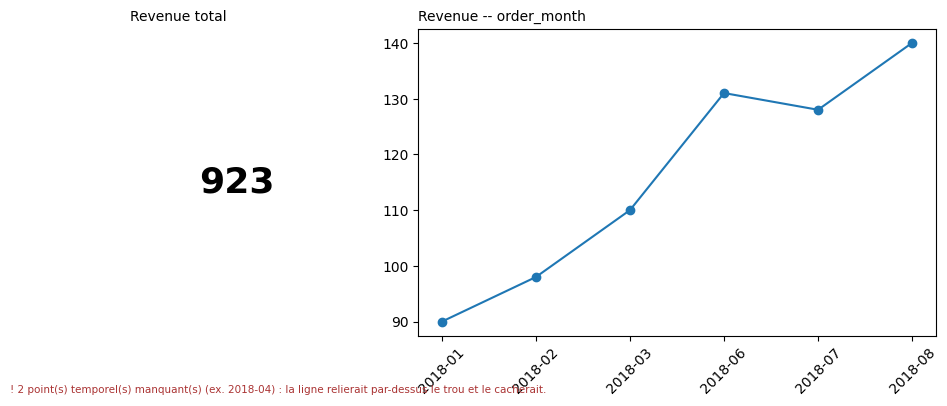

In [7]:
_ = show("line_trend"); _ = show("line_gap")

## 8. Comparaisons trompeuses

### 8.1 Comparaison bloquée par BO4-12 (cas réel du rapport d'intégration)
Demandé : −4,1 %. Sur les mêmes jours : **+34,6 %**. Tant que Sarra n'a pas décidé, la période précédente **n'est pas tracée**.


=== cmp_blocked ===
Question : Revenue by customer state, August 2018 vs July 2018
Lesson   : Real case of INTEGRATION.md: -4.1% asked, +34.6% on the same days. Comparison held back.
Chosen   : bar   (intent=comparison, requested=-, comparison_shown=False)
Ranking  :
   OK bar         70  Dimension catégorielle (27 valeurs) : barres, axe démarrant à zéro.
   OK table       30  Toujours possible, mais dernier recours pour lire une tendance ou un classement.
   no kpi_card     0  Une dimension est présente : la carte KPI est ajoutée en en-tête.
   no line         0  L'axe x (customer_state) n'est pas temporel : une ligne impliquerait un ordre qui n'existe pas.
   no pie          0  Un camembert à 27 parts est illisible (max 6) : on ne compare pas de petits angles à l'œil.
   no map          0  L'application n'a pas encore de rendu cartographique.
   ! 27 catégories : affichage du top 15 et regroupement du reste en « Autres ».
   ! [BLOCKING] La comparaison est bloquée par un contrôle (A

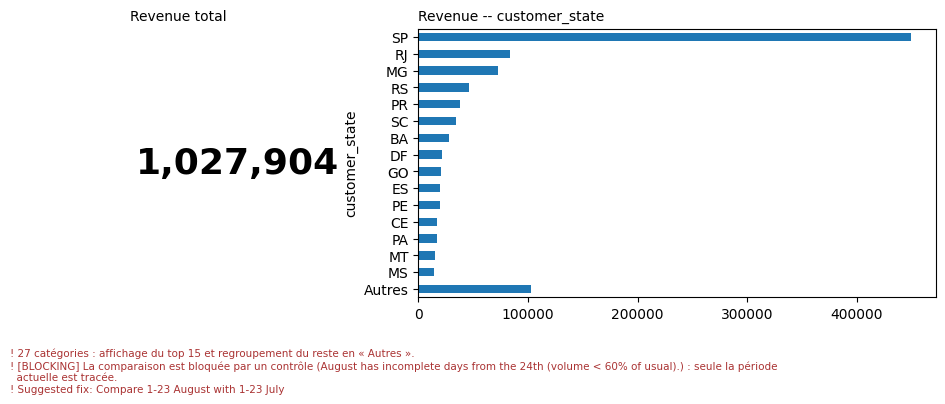

In [8]:
spec, advice, _ = show("cmp_blocked"); assert not advice.comparison_shown

### 8.2 Effet de base


=== base_effect ===
Question : Revenue August vs July
Lesson   : +6400% from a tiny base is not a performance.
Chosen   : kpi_card   (intent=total, requested=-, comparison_shown=True)
Ranking  :
   OK kpi_card   100  Aucune dimension : un seul chiffre répond à la question.
   ! Effet de base : 800 -> 52,000 (+6400%). Un gros % sur une toute petite base n'est pas une performance.


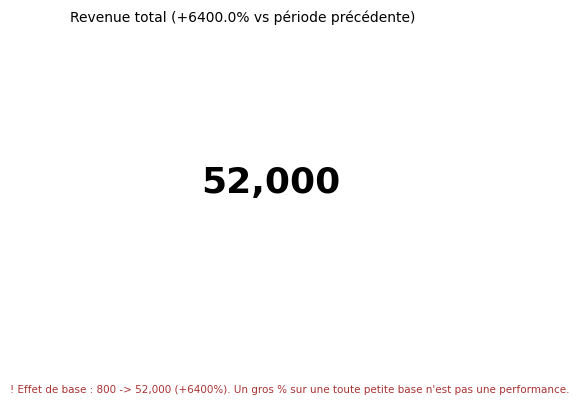

In [9]:
_ = show("base_effect")

### 8.3 Selon la décision de Sarra
Même rapport, trois décisions possibles : `pending` (rien tracé), `accepted` (chiffres ajustés en en-tête), `rejected` (comparaison tracée telle que demandée, avec l'alerte).

In [10]:
from contracts.comparisons import UserDecision
rows = []
for d in (UserDecision.PENDING, UserDecision.ACCEPTED, UserDecision.REJECTED):
    s = SC["cmp_blocked"]
    s.report = s.report.model_copy(update={"user_decision": d})
    spec, advice, frames = run_scenario(s, "fr")
    rows.append({"décision": d.value, "comparaison tracée": advice.comparison_shown,
                 "titre KPI": spec.charts[0].title, "colonnes": list(frames["c_main"].columns)})
pd.DataFrame(rows)

,décision,comparaison tracée,titre KPI,colonnes
0,pending,False,Revenue total,"[customer_state, value]"
1,accepted,False,Revenue total (+34.6% vs période précédente),"[customer_state, value]"
2,rejected,True,Revenue total (-4.1% vs période précédente),"[customer_state, value, period]"


## 9. Plusieurs KPI sur un même dashboard

Unités différentes ⇒ **un graphique par unité**, jamais d'axe partagé ni d'axe double.

In [11]:
from dashboard_ai.misleading import mixed_units
print(mixed_units({"Revenue": "BRL", "Orders": "orders", "Freight": "BRL"}, "fr").message)
print(mixed_units({"Revenue": "BRL", "Freight": "BRL"}, "fr"))

Les unités diffèrent (BRL, orders) : un graphique par unité, jamais d'axe partagé ni double.
None


## 10. L'agent dans l'orchestrateur

`dashboard_ai.agent:run` a les mêmes entrées/sorties que `app.dashboard:run` : `request`, `result`, `data`, `comparisons` → `dashboard_spec.json`. Il écrit en plus `chart_advice.json` et une ligne de journal par décision.

In [12]:
from contracts.agent import RunContext
from contracts.audit import read_events
from contracts.common import save, load
from contracts.comparisons import ComparisonReport
from contracts.dashboard import DashboardSpec
from dashboard_ai.agent import run

s = SC["pie_27"]
tmp = Path(tempfile.mkdtemp())
from contracts.analysis import AnalysisResult
from contracts.semantic import AnalysisRequest
from contracts.common import Period
req = AnalysisRequest(question=s.question, metric="Revenue", dimensions=s.dims, period=Period(start="2018-08-01", end="2018-08-31"))
res = AnalysisResult(request=req, kpi="Revenue@2.0", sql=s.sql, rows=len(s.df), value_current=s.value_current, unit="BRL", validations=[])
inputs = {"request": save(req, tmp/"request.json"), "result": save(res, tmp/"result.json"),
          "comparisons": save(ComparisonReport(has_comparison=False), tmp/"cmp.json"), "data": tmp/"result.parquet"}
s.df.to_parquet(inputs["data"], index=False)

ctx = RunContext(run_id="run_nb", agent="dashboard", inputs=inputs, output_dir=tmp/"dashboard",
                 params={"lang": "fr"}, journal=tmp/"audit.db")
out = run(ctx)
print(out.status.value, "-", out.message)
print("Fichiers :", sorted(p.name for p in (tmp/"dashboard").iterdir()))
spec = load(DashboardSpec, out.outputs["spec"])
pd.DataFrame([{"chart": c.chart_id, "type": c.chart_type.value, "x": c.x, "y": c.y, "raison": c.reason[:90]} for c in spec.charts])

success - Dashboard built: kpi_card, bar; 2 visual issue(s).
Fichiers : ['c_kpi.parquet', 'c_main.parquet', 'chart_advice.json', 'dashboard_spec.json']


,chart,type,x,y,raison
0,c_kpi,kpi_card,NaN,value,Une dimension est présente : la carte KPI est ...
1,c_main,bar,customer_state,value,"Dimension catégorielle (27 valeurs) : barres, ..."


In [13]:
events = read_events(tmp/"audit.db", run_id="run_nb")
pd.DataFrame([{"step": e.step, "decision": e.decision[:60], "rule_version": e.rule_version} for e in events])

,step,decision,rule_version
0,chart_selected,kpi_card,dashboard-rules@1.0
1,chart_selected,bar,dashboard-rules@1.0
2,visual_issue,WARNING: requested_chart_refused,dashboard-rules@1.0
3,visual_issue,WARNING: too_many_categories,dashboard-rules@1.0


## 11. Validation

Les assertions ci-dessous échouent si le comportement attendu change.

In [14]:
from contracts.dashboard import ChartType
expect = {"kpi_total": ChartType.KPI_CARD, "bar_27": ChartType.BAR, "pie_share": ChartType.PIE, "pie_27": ChartType.BAR,
          "pie_distinct": ChartType.BAR, "line_trend": ChartType.LINE, "line_gap": ChartType.LINE, "cmp_blocked": ChartType.BAR}
SC = {s.name: s for s in scenarios()}
for name, want in expect.items():
    _, adv, _ = run_scenario(SC[name], "en")
    got = adv.decisions[-1].chosen
    assert got == want, (name, got, want)
    print(f"OK  {name:<14} -> {got.value}")
_, adv, _ = run_scenario(SC["cmp_blocked"], "en"); assert not adv.comparison_shown
_, adv, _ = run_scenario(SC["base_effect"], "en"); assert any(i.kind.value == "base_effect" for i in adv.decisions[-1].issues)
print("\nAll assertions passed.")

OK  kpi_total      -> kpi_card
OK  bar_27         -> bar
OK  pie_share      -> pie
OK  pie_27         -> bar
OK  pie_distinct   -> bar
OK  line_trend     -> line
OK  line_gap       -> line
OK  cmp_blocked    -> bar

All assertions passed.


## 12. Intégration

1. `contracts/pipeline.py` : `entrypoint="app.dashboard:run"` → `entrypoint="dashboard_ai.agent:run"` (une ligne ; le contrat `DashboardSpec` ne change pas).
2. `app/app.py` : ajouter le rendu `pie` (aujourd'hui seuls `kpi_card`, `bar`, `line`, `table` sont dessinés) et, pour les barres, garder l'axe à zéro.
3. Paramètre optionnel `lang="fr"` pour les messages en français ; `rules={...}` pour surcharger les seuils.